# 285. Does pooling kmerseek calls across a human paralog family rescue Ced9 → BCL2?

**Question.** In [notebook 241](241_alphabet_ranking_BCL2-Ced9_P66-CD47_BHF.ipynb)'s search
of *C. elegans* CED-9 (Ced9, UniProt P41958) against the human proteome, no call on BCL2
passes E < 10. But Ced9's BH1 motif lands in register on the BH1 motif of several BCL2
relatives (MCL1 E = 16.7, BAK1 E = 23.9; [PR 125](https://github.com/seanome/2024-kmerseek-analysis/pull/125),
`284_ced9_bcl2_family_hits.csv`). Counting agreement across alphabets failed in PR 125.
Here the calls are pooled across the members of the target's own paralog family instead,
at the same residue of the query. Does BCL2's family then rank near the top for Ced9?
Second case: the Lyme disease protein P66 (*Borrelia*) → human CD47.

**Decision this informs.** If pooling across a family rescues BCL2, kmerseek's output can be
read at the family level (a pooled family score next to the per-protein E-value), and the
paper can claim Ced9 → BCL2 as a family-level detection. If not, Ced9 → BCL2 stays out of
reach of kmerseek's region evidence, and we stop trying score combinations on this pair.

**Rule, written and committed before any group was scored**
([d184330](https://github.com/seanome/2024-kmerseek-analysis/commit/d184330),
`scripts/285_family_pooled_evidence.py`):

1. *Groups.* Two human genes are in one group when Ensembl 115 lists them as paralogs (any
   homology type); a group is a connected set of such pairs. Ensembl builds its paralog list
   from gene trees, so a group is the human genes of one gene tree. Nothing about Ced9, P66
   or kmerseek is used. A gene with no paralog is a group of one.
2. *Per call.* kmerseek's region E-value is for the whole database (the expected number of
   calls this good among all 19_732 proteins). The chance that one given protein gets such a
   call is $p = 1 - e^{-E \cdot L_t / L_{db}}$, with $L_t$ the protein's length and
   $L_{db}$ the database's total length. A region with no E-value fit gives $p = 1$.
3. *Same position* means the same query residue. For each protein and each residue of the
   query, $p$ is the lowest over all calls (any of the 152 alphabet-ksize settings) covering
   that residue, and 1 where there is no call.
4. *Group score.* Fisher's method over **all** $n$ members at each query residue,
   $X = -2\sum_m \ln p_m$ against a χ² distribution with $2n$ degrees of freedom; members
   with no call count with $p = 1$, so a big group is not rewarded for its size. The group's
   score is its lowest Fisher $p$ over the query's residues. **Lower is better**; $p$ near 1
   means no evidence.
5. *Nulls.* (a) 1_000 random sets of human proteins with the same number of members, scored
   the same way. (b) 20 dipeptide-shuffled copies of the query (same length, same count of
   every adjacent residue pair), from `notebooks/284_shuffle_agreement.py`.

**Pass** if the partner's group ranks in the **top 10 of the 7_212 groups**, AND scores
better than **95% of the random sets**, AND better than **95% of the shuffled queries**.

## Data

- **Query and targets.** Notebook 241's search ([PR 46](https://github.com/seanome/2024-kmerseek-analysis/pull/46),
  run on Sherlock 2026-09-23): queries Ced9 (P41958, 280 aa) and P66 (from notebook 241's
  `queries.fa`); target database the 19_732 GENCODE v49 canonical human proteins; 152
  alphabet-ksize settings over 19 alphabets; every region kept (8_295_664 regions,
  `~/data/botryllus/alphabet-ranking-three-cases/regions.parquet`, a copy of
  `$SCRATCH/241-alphabet-ranking/regions.parquet`). Region coordinates are 0-based,
  end-exclusive and ungapped; this notebook prints them 1-based.
- **Paralogs.** Ensembl 115 BioMart (`sep2025.archive.ensembl.org`, the release GENCODE v49
  was made with), `hsapiens_paralog_*` attributes for protein-coding genes, fetched
  2026-10-13 and cached at `~/data/ensembl/115/human_paralogs.tsv`
  (`scripts/285_paralog_groups.py`).
- **BH motifs.** UniProt motif features of Ced9 and the nine BCL-2 family members, fetched
  2026-10-13 (`notebooks/285_bh_motifs_uniprot.csv`). Each UniProt sequence was checked to
  equal the GENCODE protein before its coordinates were used.
- **Tables this notebook reads**, all written by `scripts/285_family_pooled_evidence.py`:
  `notebooks/285_*.csv`.

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import chi2

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(90)
FIG = Path("../figures/285")
NB = Path(".")
TOOL = (
    "kmerseek, 152 alphabet-ksize settings (19 alphabets), notebook 241's search. "
    "Target database: 19_732 GENCODE v49 canonical human proteins"
)
summary = pl.read_csv(NB / "285_family_pooling_summary.csv")
groups = pl.read_csv(NB / "285_paralog_groups_ensembl115.csv")
calls = pl.read_csv(NB / "285_case_group_calls.csv")
track = pl.read_csv(NB / "285_case_group_residue_evidence.csv")
allg = pl.read_csv(NB / "285_posthoc_copies_once.csv")
rand = pl.read_csv(NB / "285_random_group_null.csv")
motifs = pl.read_csv(NB / "285_bh_motifs_uniprot.csv")
C = pf.OKABE_ITO

## 1. The groups

The rule gives 7_212 groups for the 19_732 proteins. BCL2's group is the whole BCL-2
family: BAK1, BAX, BCL2, BCL2A1, BCL2L1, BCL2L10, BCL2L2, BOK and MCL1. CD47 has no paralog
in Ensembl, so its group is CD47 alone and pooling cannot change its score.

19_732 proteins in 7_212 groups; 4_371 genes have no paralog; largest group 177
BCL2 group: BAK1 BAX BCL2 BCL2A1 BCL2L1 BCL2L10 BCL2L2 BOK MCL1
CD47 group: CD47
shape: (12, 2)
┌─────┬──────────┐
│ n   ┆ n_groups │
│ --- ┆ ---      │
│ u32 ┆ u32      │
╞═════╪══════════╡
│ 1   ┆ 4371     │
│ 2   ┆ 1160     │
│ 3   ┆ 587      │
│ 4   ┆ 296      │
│ 5   ┆ 158      │
│ 6   ┆ 114      │
│ 7   ┆ 77       │
│ 8   ┆ 64       │
│ 9   ┆ 42       │
│ 10  ┆ 34       │
│ 11  ┆ 30       │
│ 12  ┆ 22       │
└─────┴──────────┘


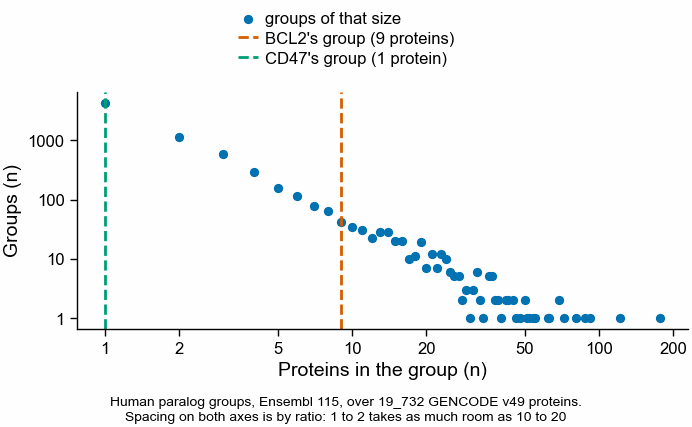

In [2]:
sizes = groups.group_by("group_id").agg(n=pl.len())
dist = sizes.group_by("n").agg(n_groups=pl.len()).sort("n")
print(
    f"{groups.height:_} proteins in {sizes.height:_} groups; "
    f"{(sizes['n'] == 1).sum():_} genes have no paralog; largest group {sizes['n'].max()}"
)
for gene in ["BCL2", "CD47"]:
    gid = groups.filter(pl.col("gene") == gene)["group_id"][0]
    print(
        gene,
        "group:",
        " ".join(groups.filter(pl.col("group_id") == gid)["gene"].sort()),
    )
print(dist.head(12))

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
ax.scatter(
    dist["n"], dist["n_groups"], s=8, color=C["blue"], label="groups of that size"
)
for gene, col in [("BCL2", C["vermillion"]), ("CD47", C["bluish_green"])]:
    n = sizes.filter(
        pl.col("group_id") == groups.filter(pl.col("gene") == gene)["group_id"][0]
    )["n"][0]
    ax.axvline(
        n,
        color=col,
        lw=1,
        ls="--",
        label=f"{gene}'s group ({n} protein{'s' if n > 1 else ''})",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ticks = [1, 2, 5, 10, 20, 50, 100, 200]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.minorticks_off()
yt = [1, 10, 100, 1000]
ax.set_yticks(yt, [str(t) for t in yt])
ax.set_xlabel("Proteins in the group (n)")
ax.set_ylabel("Groups (n)")
pf.shared_legend(fig, ncol=1)
fig.supxlabel(
    "Human paralog groups, Ensembl 115, over 19_732 GENCODE v49 proteins.\n"
    "Spacing on both axes is by ratio: 1 to 2 takes as much room as 10 to 20",
    fontsize=5,
)
pf.save(fig, FIG / "285_paralog_group_sizes_ensembl115")

## 2. Ced9's evidence on each BCL-2 family member, residue by residue

Top: Ced9 as a line, with its BH4, BH1 and BH2 motifs (UniProt) as boxes. Middle: one row
per family member; the colour is the strongest per-protein evidence, $-\log_{10} p$, from
any call covering that Ced9 residue. White means no call. Bottom: the pooled family score
at each residue (Fisher's method over all nine members); higher is stronger evidence.

How to read it: if the family's evidence is real, the members' calls should pile up on one
motif. They do on BH1: the pooled score peaks at Ced9 residue 168, inside BH1 (160-179).

pooled family score: lowest Fisher p = 10^-7.16 at Ced9 residue 168
shape: (9, 4)
┌─────────┬─────────────────────────┬────────────────────────┬──────────────────────┐
│ gene    ┆ strongest_minus_log10_p ┆ at_ced9_residue_1based ┆ minus_log10_p_at_168 │
│ ---     ┆ ---                     ┆ ---                    ┆ ---                  │
│ str     ┆ f64                     ┆ i64                    ┆ f64                  │
╞═════════╪═════════════════════════╪════════════════════════╪══════════════════════╡
│ BAK1    ┆ 3.35                    ┆ 163                    ┆ 3.35                 │
│ BAX     ┆ 1.58                    ┆ 71                     ┆ 0.73                 │
│ BCL2    ┆ 1.39                    ┆ 78                     ┆ 0.68                 │
│ BCL2A1  ┆ 2.54                    ┆ 156                    ┆ 2.54                 │
│ MCL1    ┆ 3.29                    ┆ 168                    ┆ 3.29                 │
│ BCL2L1  ┆ 2.01                    ┆ 156                 

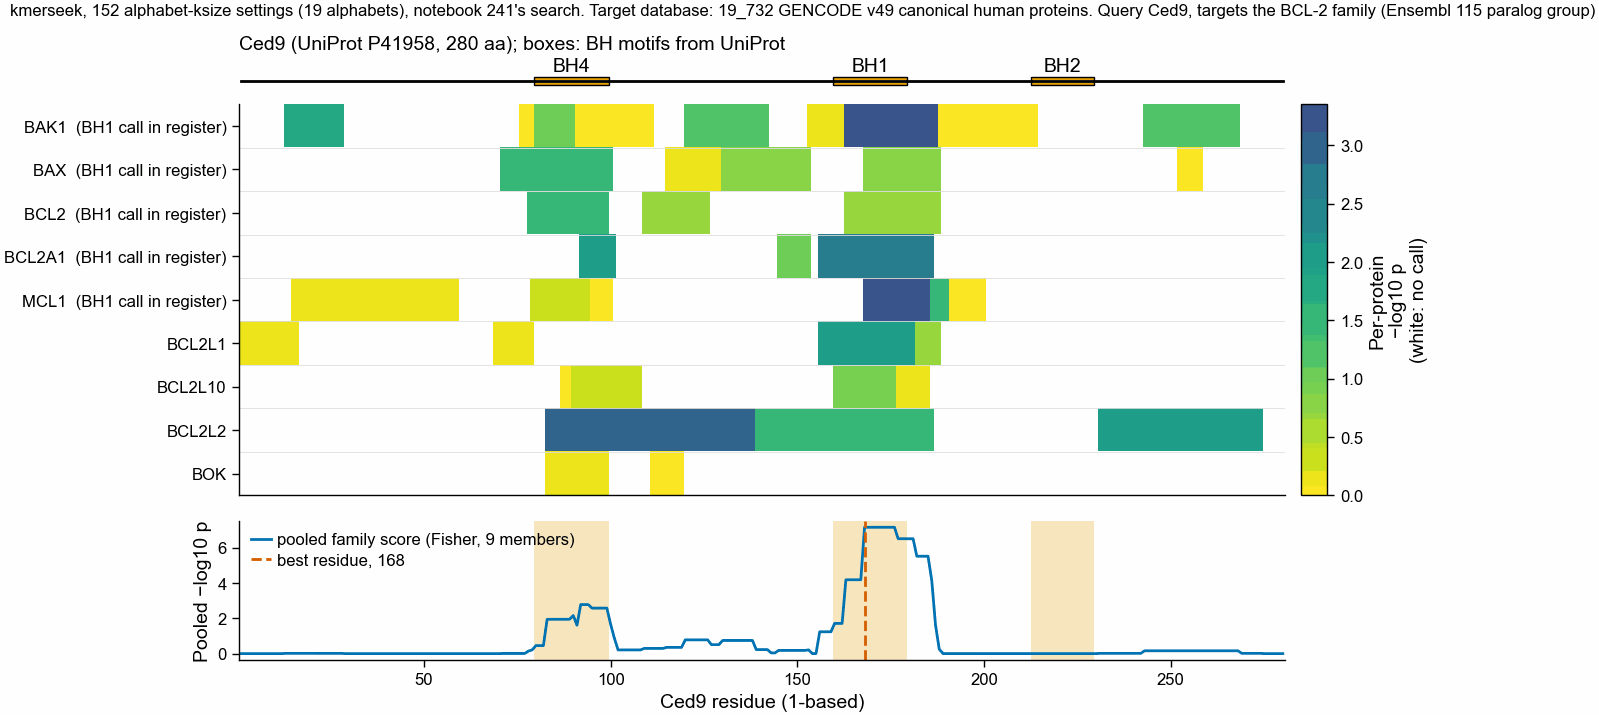

In [3]:
q = track.filter(pl.col("query") == "Ced9")
cg = calls.filter(pl.col("query") == "Ced9")
order = (
    cg.with_columns(reg=pl.col("in_register_bh1").fill_null(False))
    .sort(["reg", "gene"], descending=[True, False])["gene"]
    .to_list()
)
L = q["residue0"].max() + 1
M = np.vstack(
    [
        q.filter(pl.col("gene") == g).sort("residue0")["neg_ln_p"].to_numpy()
        for g in order
    ]
)
M10 = M / np.log(10)  # -log10 p per protein
n = len(order)
pooled = -chi2.logsf(2 * M.sum(axis=0), 2 * n) / np.log(
    10
)  # -log10 Fisher p per residue
best = int(np.argmax(pooled))
s = summary.filter(pl.col("query") == "Ced9").row(0, named=True)
assert (
    abs(pooled[best] + s["case_group_log10_p"]) < 1e-9
    and best == s["case_group_best_residue0"]
)
tab = pl.DataFrame(
    {
        "gene": order,
        "strongest_minus_log10_p": M10.max(axis=1).round(2),
        "at_ced9_residue_1based": M10.argmax(axis=1) + 1,
        "minus_log10_p_at_168": M10[:, best].round(2),
    }
)
print(
    f"pooled family score: lowest Fisher p = 10^{-pooled[best]:.2f} at Ced9 residue {best + 1}"
)
print(tab)

ced = motifs.filter(pl.col("gene") == "Ced9")
fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 92 * pf.MM), layout="constrained")
gs = fig.add_gridspec(3, 2, height_ratios=[0.5, n, 3.2], width_ratios=[40, 1])
a0, a1, a2 = (
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[2, 0]),
)
cax = fig.add_subplot(gs[1, 1])
x = np.arange(1, L + 1)
a0.plot([1, L], [0, 0], color="black", lw=1)
for r in ced.iter_rows(named=True):
    a0.add_patch(
        mpl.patches.Rectangle(
            (r["start1"] - 0.5, -0.4),
            r["end1"] - r["start1"] + 1,
            0.8,
            facecolor=C["orange"],
            edgecolor="black",
            lw=0.5,
        )
    )
    a0.text((r["start1"] + r["end1"]) / 2, 0.55, r["motif"], ha="center", va="bottom")
a0.set_ylim(-0.6, 1.4)
a0.set_yticks([])
a0.set_xlim(0.5, L + 0.5)
a0.spines[["left", "bottom"]].set_visible(False)
a0.set_xticks([])
a0.set_title("Ced9 (UniProt P41958, 280 aa); boxes: BH motifs from UniProt", loc="left")
cmap = mpl.colors.ListedColormap(
    plt.get_cmap("viridis")(np.linspace(0.25, 1, 256))[::-1]
)
cmap.set_bad("white")
img = np.ma.masked_where(M10 <= 0, M10)
im = a1.imshow(
    img,
    aspect="auto",
    cmap=cmap,
    interpolation="nearest",
    extent=(0.5, L + 0.5, n - 0.5, -0.5),
    vmin=0,
    vmax=float(M10.max()),
)
labels = [
    f"{g}{'  (BH1 call in register)' if cg.filter(pl.col('gene') == g)['in_register_bh1'][0] else ''}"
    for g in order
]
a1.set_yticks(range(n), labels)
for i in range(n):
    a1.axhline(i + 0.5, color="#DDDDDD", lw=0.3)
a1.set_xlim(0.5, L + 0.5)
a1.set_xticks([])
fig.colorbar(im, cax=cax, label="Per-protein\n−log10 p\n(white: no call)")
a2.plot(
    x, pooled, color=C["blue"], lw=1, label="pooled family score (Fisher, 9 members)"
)
a2.axvline(
    best + 1, color=C["vermillion"], ls="--", lw=1, label=f"best residue, {best + 1}"
)
for r in ced.iter_rows(named=True):
    a2.axvspan(r["start1"] - 0.5, r["end1"] + 0.5, color=C["orange"], alpha=0.25, lw=0)
a2.set_xlim(0.5, L + 0.5)
a2.set_xlabel("Ced9 residue (1-based)")
a2.set_ylabel("Pooled −log10 p")
a2.legend(loc="upper left", frameon=False)
fig.suptitle(
    TOOL + ". Query Ced9, targets the BCL-2 family (Ensembl 115 paralog group)",
    fontsize=6,
    x=0.01,
    ha="left",
)
pf.save(fig, FIG / "285_ced9_bcl2_family_evidence_by_residue")

## 3. The real residues at Ced9 residue 168

For each family member, the call with the lowest per-protein $p$ that covers Ced9 residue
168. kmerseek regions are ungapped, so each pair is two equal-length stretches; `|` marks an
identical residue. A call is **in register on BH1** when its diagonal (target start minus
query start) is within 1 residue of the diagonal that puts Ced9's BH1 on the member's own
BH1 (UniProt), the rule of `scripts/284_ced9_bcl2_family_hits.py`. This check was added after
the first run and is not part of the decision.

shape: (8, 10)
┌─────────┬──────────────────────┬─────┬─────────┬───┬────────┬─────────────────┬─────────────┬────────────────┐
│ gene    ┆ alphabet             ┆ k   ┆ ced9    ┆ … ┆ p      ┆ in_register_bh1 ┆ n_identical ┆ aligned_length │
│ ---     ┆ ---                  ┆ --- ┆ ---     ┆   ┆ ---    ┆ ---             ┆ ---         ┆ ---            │
│ str     ┆ str                  ┆ i64 ┆ str     ┆   ┆ f64    ┆ bool            ┆ i64         ┆ i64            │
╞═════════╪══════════════════════╪═════╪═════════╪═══╪════════╪═════════════════╪═════════════╪════════════════╡
│ BAK1    ┆ dayhoff6             ┆ 11  ┆ 163-187 ┆ … ┆ 0.0004 ┆ true            ┆ 6           ┆ 25             │
│ BAX     ┆ dayhoff6             ┆ 7   ┆ 168-188 ┆ … ┆ 0.1869 ┆ true            ┆ 5           ┆ 21             │
│ BCL2    ┆ hp_lehninger2        ┆ 19  ┆ 163-188 ┆ … ┆ 0.2097 ┆ true            ┆ 5           ┆ 26             │
│ BCL2A1  ┆ dayhoff6             ┆ 7   ┆ 156-186 ┆ … ┆ 0.0029 ┆ true            ┆

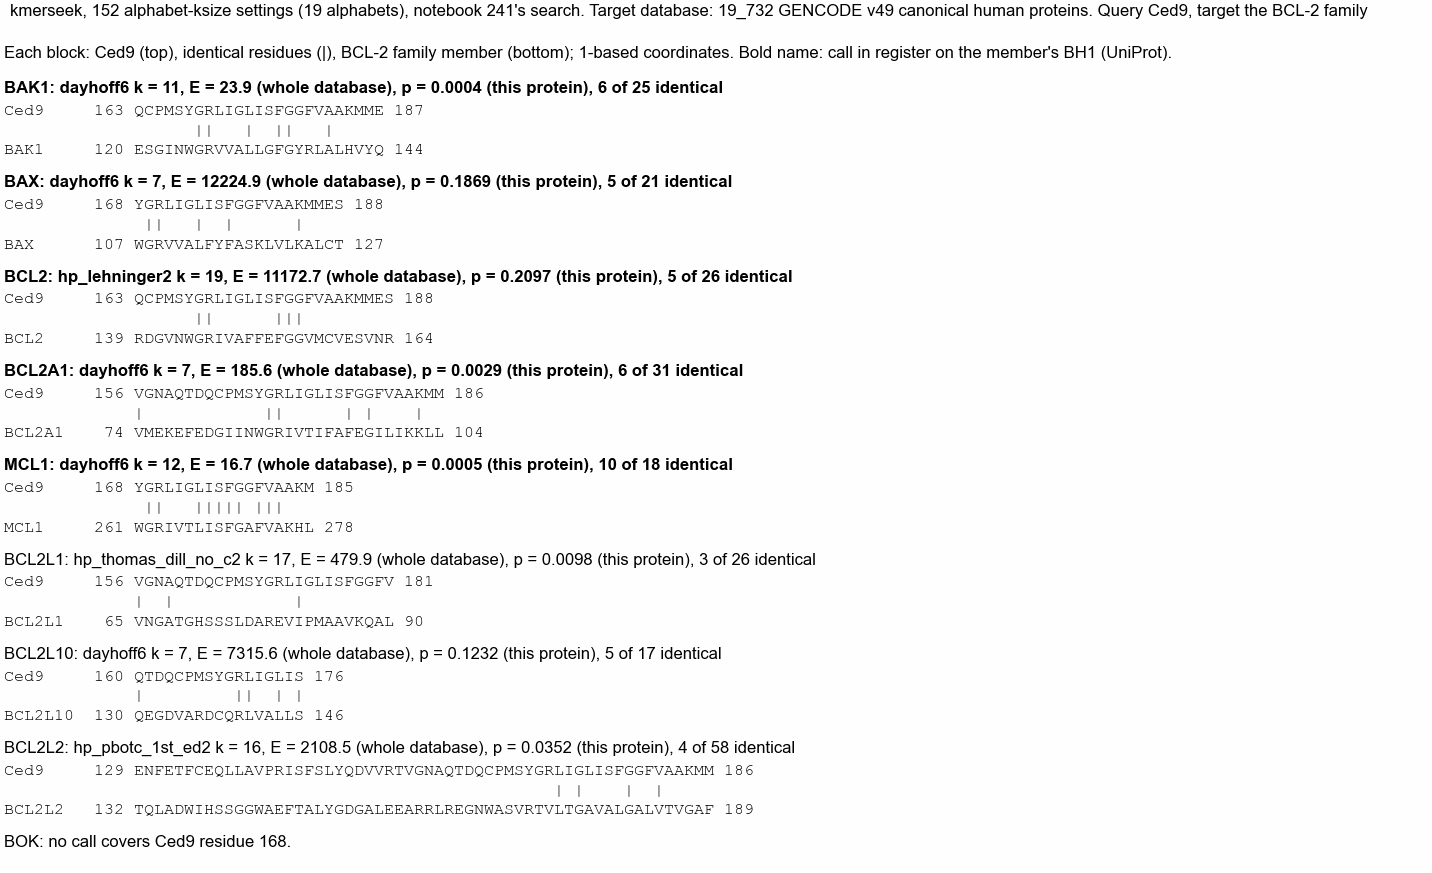

In [4]:
cols = [
    "gene",
    "alphabet",
    "k",
    "query_start0",
    "query_end0",
    "target_start0",
    "target_end0",
    "evalue_database",
    "p_protein",
    "in_register_bh1",
    "n_identical",
    "aligned_length",
]
t = (
    cg.filter(pl.col("has_call"))
    .select(cols)
    .with_columns(
        ced9=pl.format("{}-{}", pl.col("query_start0") + 1, pl.col("query_end0")),
        member=pl.format("{}-{}", pl.col("target_start0") + 1, pl.col("target_end0")),
        E=pl.col("evalue_database").round(1),
        p=pl.col("p_protein").round(4),
    )
)
print(
    t.select(
        "gene",
        "alphabet",
        "k",
        "ced9",
        "member",
        "E",
        "p",
        "in_register_bh1",
        "n_identical",
        "aligned_length",
    )
)
print("BOK: no call covers Ced9 residue 168")
rows = cg.filter(pl.col("has_call")).sort(
    "in_register_bh1", "gene", descending=[True, False]
)
for r in rows.iter_rows(named=True):
    print(
        f"\n{r['gene']}  {r['alphabet']} k={r['k']}  E = {r['evalue_database']:.1f} "
        f"(database), p = {r['p_protein']:.4f} (this protein)  "
        f"{r['n_identical']} of {r['aligned_length']} identical  "
        f"in register on BH1: {'yes' if r['in_register_bh1'] else 'no'}"
    )
    print(
        f"  {'Ced9':<8}{r['query_start0'] + 1:>4} {r['query_residues']} {r['query_end0']}"
    )
    print(f"  {'':<8}{'':>4} {r['match']}")
    print(
        f"  {r['gene']:<8}{r['target_start0'] + 1:>4} {r['target_residues']} {r['target_end0']}"
    )

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 112)
ax.axis("off")
y = 0
mono = {"family": "monospace", "size": 6}
ax.text(
    0,
    y,
    "Each block: Ced9 (top), identical residues (|), BCL-2 family member (bottom); "
    "1-based coordinates. Bold name: call in register on the member's BH1 (UniProt).",
    size=6,
)
y -= 1.6
for r in rows.iter_rows(named=True):
    ax.text(
        0,
        y,
        f"{r['gene']}: {r['alphabet']} k = {r['k']}, E = {r['evalue_database']:.1f} "
        f"(whole database), p = {r['p_protein']:.4f} (this protein), "
        f"{r['n_identical']} of {r['aligned_length']} identical",
        size=6,
        weight="bold" if r["in_register_bh1"] else "normal",
    )
    ax.text(
        0,
        y - 1,
        f"Ced9    {r['query_start0'] + 1:>4} {r['query_residues']} {r['query_end0']}",
        **mono,
    )
    ax.text(0, y - 1.9, f"             {r['match']}", **mono)
    ax.text(
        0,
        y - 2.8,
        f"{r['gene']:<8}{r['target_start0'] + 1:>4} {r['target_residues']} {r['target_end0']}",
        **mono,
    )
    y -= 4.3
ax.text(0, y, "BOK: no call covers Ced9 residue 168.", size=6)
ax.set_xlim(0, 1)
ax.set_ylim(y - 1, 1)
fig.suptitle(
    TOOL + ". Query Ced9, target the BCL-2 family", fontsize=6, x=0.01, ha="left"
)
pf.save(fig, FIG / "285_ced9_bcl2_family_residues_at_168")

## 4. Where the partner's group ranks among all 7_212 groups

Each point is one human paralog group: x is its number of proteins, y its pooled score
($-\log_{10}$ of the lowest Fisher $p$; **higher is stronger evidence**). The dashed line is
the 10th group's score, the decision rule's cut.

shape: (2, 15)
┌───────┬─────────┬─────────────────┬────────────────────┬───┬────────────┬─────────────┬─────────────────────┬────────────┐
│ query ┆ partner ┆ case_group_size ┆ case_group_log10_p ┆ … ┆ n_proteins ┆ best_member ┆ best_member_log10_p ┆ pass_top10 │
│ ---   ┆ ---     ┆ ---             ┆ ---                ┆   ┆ ---        ┆ ---         ┆ ---                 ┆ ---        │
│ str   ┆ str     ┆ i64             ┆ f64                ┆   ┆ i64        ┆ str         ┆ f64                 ┆ bool       │
╞═══════╪═════════╪═════════════════╪════════════════════╪═══╪════════════╪═════════════╪═════════════════════╪════════════╡
│ Ced9  ┆ BCL2    ┆ 9               ┆ -7.160471          ┆ … ┆ 19732      ┆ BAK1        ┆ -3.352784           ┆ false      │
│ P66   ┆ CD47    ┆ 1               ┆ -1.700414          ┆ … ┆ 19732      ┆ CD47        ┆ -1.700414           ┆ false      │
└───────┴─────────┴─────────────────┴────────────────────┴───┴────────────┴─────────────┴─────────────────────

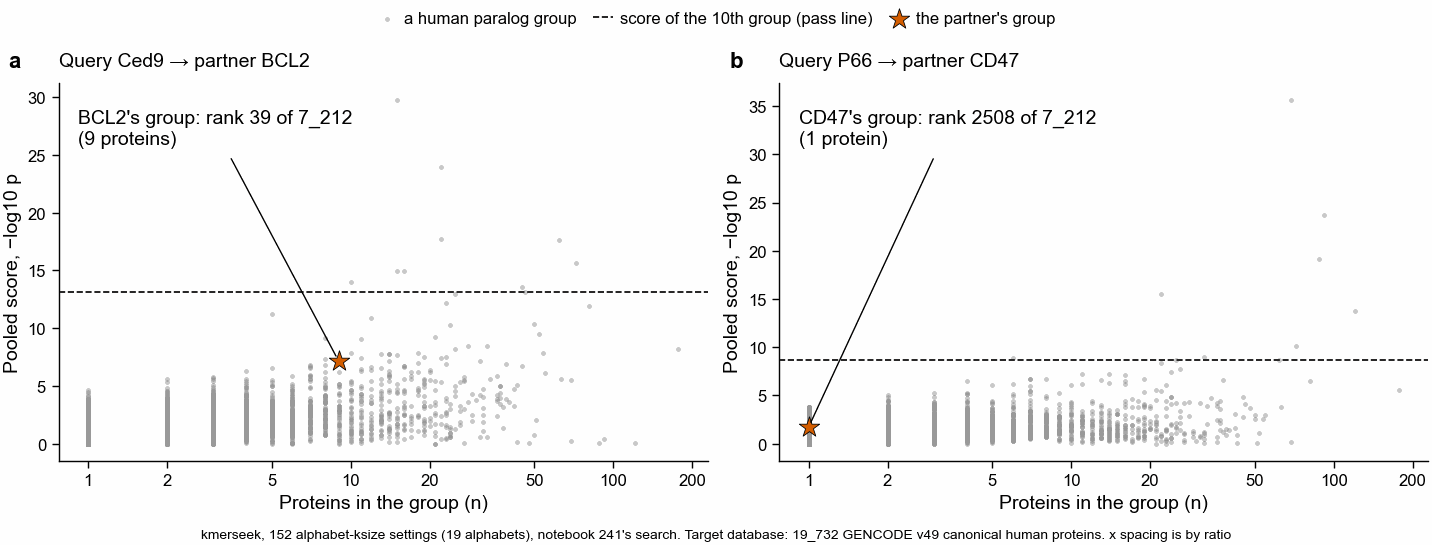

In [5]:
print(
    summary.select(
        "query",
        "partner",
        "case_group_size",
        "case_group_log10_p",
        "case_group_rank",
        "n_groups",
        "case_group_n_tied",
        "case_group_rank_same_size",
        "n_groups_same_size",
        "partner_alone_log10_p",
        "partner_alone_rank",
        "n_proteins",
        "best_member",
        "best_member_log10_p",
        "pass_top10",
    )
)
for q in ["Ced9", "P66"]:
    print(f"\n{q}: top 10 groups by pooled score")
    print(
        allg.filter(pl.col("query") == q)
        .sort("log10_p_rule", "group_id")
        .head(10)
        .select("n_proteins", "log10_p_rule", pl.col("genes").str.slice(0, 80))
    )

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 70, ncols=2)
for ax, (q, partner, letter) in zip(axs, [("Ced9", "BCL2", "a"), ("P66", "CD47", "b")]):
    d = allg.filter(pl.col("query") == q)
    s = summary.filter(pl.col("query") == q).row(0, named=True)
    ax.scatter(
        d["n_proteins"],
        -d["log10_p_rule"],
        s=3,
        color=pf.GREY,
        lw=0,
        alpha=0.6,
        label="a human paralog group" if letter == "a" else None,
    )
    cut = -d.sort("log10_p_rule")["log10_p_rule"][9]
    ax.axhline(
        cut,
        color="black",
        ls="--",
        lw=0.6,
        label="score of the 10th group (pass line)" if letter == "a" else None,
    )
    ax.scatter(
        [s["case_group_size"]],
        [-s["case_group_log10_p"]],
        marker="*",
        s=60,
        color=C["vermillion"],
        edgecolor="black",
        lw=0.3,
        zorder=3,
        label="the partner's group" if letter == "a" else None,
    )
    ax.annotate(
        f"{partner}'s group: rank {s['case_group_rank']} of {s['n_groups']:_}\n"
        f"({s['case_group_size']} protein{'s' if s['case_group_size'] > 1 else ''})",
        (s["case_group_size"], -s["case_group_log10_p"]),
        xytext=(0.03, 0.93),
        textcoords="axes fraction",
        va="top",
        arrowprops=dict(arrowstyle="-", lw=0.5),
    )
    ax.set_xscale("log")
    ticks = [1, 2, 5, 10, 20, 50, 100, 200]
    ax.set_xticks(ticks, [str(t) for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel("Proteins in the group (n)")
    ax.set_ylabel("Pooled score, −log10 p")
    ax.set_title(f"Query {q} → partner {partner}", loc="left")
    pf.panel_label(ax, letter)
pf.shared_legend(fig, ncol=3)
fig.supxlabel(TOOL + ". x spacing is by ratio", fontsize=5)
pf.save(fig, FIG / "285_group_rank_ced9_p66_gencode_v49")

## 5. Nulls: random protein sets of the same size, and shuffled queries

**(a) Random sets.** 1_000 sets of human proteins drawn at random (not paralogs of each
other), with as many members as the partner's group, scored on the real query. The grey
histogram is those sets; blue ticks are the real paralog groups of the same size; the star
is the partner's group.

**(b) Dipeptide-shuffled queries: pending.** `notebooks/284_shuffle_agreement.py` (PR 125)
searches 20 shuffles each of Ced9, P66 and BHF on all 152 settings with every region kept.
As of 2026-10-13 it has not run: its job (47649174) found 0 of 152 human indexes, because
notebook 283's index rebuild (job 47648977) stops on a `plan.json` checksum that differs
from notebook 241's. When its regions exist, this rerun adds them to the decision:
`python3 scripts/285_family_pooled_evidence.py --shuffle-regions <NB284_DIR>`.

shape: (2, 10)
┌───────┬─────────┬───────────┬─────────────────────┬───┬──────────────────┬───────────────────────────────┬─────────────────────────┬─────────────────────────────────────────┐
│ query ┆ partner ┆ n_members ┆ partner_group_score ┆ … ┆ random_sets_95th ┆ random_sets_as_good_or_better ┆ real_same_size_groups_n ┆ real_same_size_groups_as_good_or_better │
│ ---   ┆ ---     ┆ ---       ┆ ---                 ┆   ┆ ---              ┆ ---                           ┆ ---                     ┆ ---                                     │
│ str   ┆ str     ┆ i64       ┆ f64                 ┆   ┆ f64              ┆ i64                           ┆ i64                     ┆ i64                                     │
╞═══════╪═════════╪═══════════╪═════════════════════╪═══╪══════════════════╪═══════════════════════════════╪═════════════════════════╪═════════════════════════════════════════╡
│ Ced9  ┆ BCL2    ┆ 9         ┆ 7.16                ┆ … ┆ 3.94             ┆ 0                      

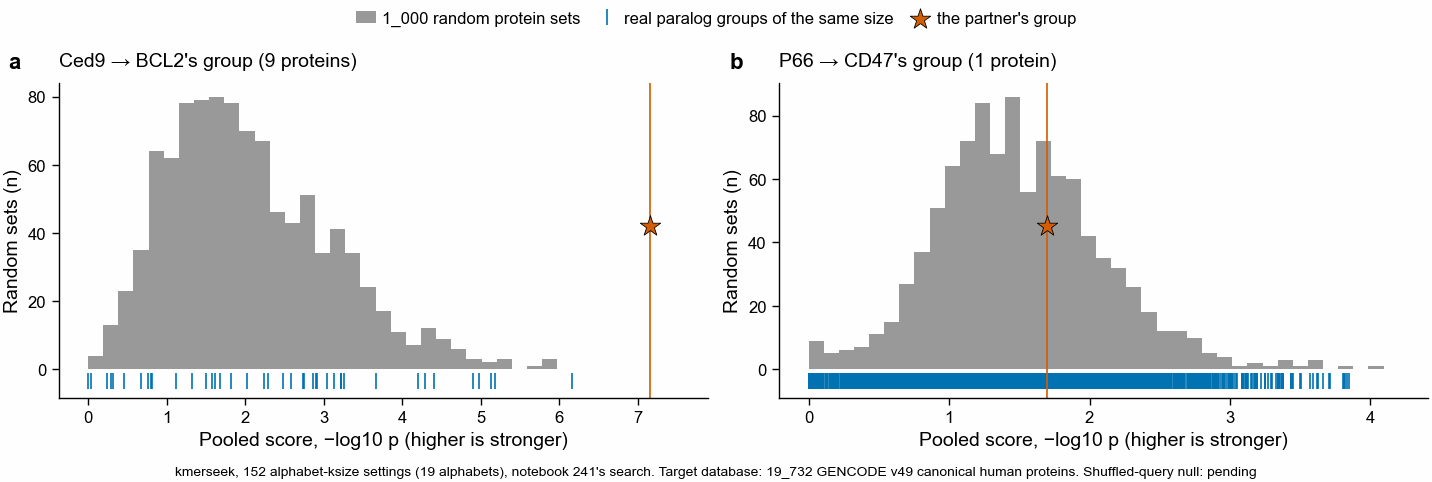

In [6]:
tabs = []
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=2)
for ax, (q, partner, letter) in zip(axs, [("Ced9", "BCL2", "a"), ("P66", "CD47", "b")]):
    s = summary.filter(pl.col("query") == q).row(0, named=True)
    r = -rand.filter(pl.col("query") == q)["log10_p"].to_numpy()
    real = -allg.filter(
        (pl.col("query") == q)
        & (pl.col("n_proteins") == s["case_group_size"])
        & (pl.col("group_id") != s["case_group_id"])
    )["log10_p_rule"].to_numpy()
    v = -s["case_group_log10_p"]
    tabs.append(
        {
            "query": q,
            "partner": partner,
            "n_members": s["case_group_size"],
            "partner_group_score": round(v, 2),
            "random_sets_n": len(r),
            "random_sets_median": round(float(np.median(r)), 2),
            "random_sets_95th": round(float(np.quantile(r, 0.95)), 2),
            "random_sets_as_good_or_better": int((r >= v).sum()),
            "real_same_size_groups_n": len(real),
            "real_same_size_groups_as_good_or_better": int((real >= v).sum()),
        }
    )
    bins = np.linspace(0, max(r.max(), v, real.max() if len(real) else 0) * 1.05, 40)
    ax.hist(
        r,
        bins=bins,
        color=pf.GREY,
        label="1_000 random protein sets" if letter == "a" else None,
    )
    top = ax.get_ylim()[1]
    if len(real):
        ax.plot(
            real,
            np.full(len(real), -0.04 * top),
            "|",
            color=C["blue"],
            ms=6,
            mew=0.6,
            label="real paralog groups of the same size" if letter == "a" else None,
        )
    ax.scatter(
        [v],
        [0.5 * top],
        marker="*",
        s=60,
        color=C["vermillion"],
        edgecolor="black",
        lw=0.3,
        zorder=3,
        label="the partner's group" if letter == "a" else None,
    )
    ax.axvline(v, color=C["vermillion"], lw=0.6)
    ax.set_ylim(-0.1 * top, top)
    ax.set_xlabel("Pooled score, −log10 p (higher is stronger)")
    ax.set_ylabel("Random sets (n)")
    ax.set_title(
        f"{q} → {partner}'s group ({s['case_group_size']} protein"
        f"{'s' if s['case_group_size'] > 1 else ''})",
        loc="left",
    )
    pf.panel_label(ax, letter)
pf.shared_legend(fig, ncol=3)
fig.supxlabel(TOOL + ". Shuffled-query null: pending", fontsize=5)
pf.save(fig, FIG / "285_random_set_null_ced9_p66_gencode_v49")
print(pl.DataFrame(tabs))

## 6. Post-hoc: counting near-identical copies once

Added after the first run, not part of the decision. Ced9's top group was 15 histone H4
genes, 14 of which encode the same protein; Fisher's method counted the one chance call 14
times. Here members of a group at least 90% identical to each other (both of Ensembl's %id
columns) are merged, their strongest evidence per residue kept, and $n$ counts merged
members. Points on the diagonal did not change; points below it lost evidence they had from
copies.

shape: (2, 5)
┌───────┬─────────┬───────────────────────────┬───────────────────┬──────────────────────────┐
│ query ┆ partner ┆ groups_with_merged_copies ┆ partner_rank_rule ┆ partner_rank_copies_once │
│ ---   ┆ ---     ┆ ---                       ┆ ---               ┆ ---                      │
│ str   ┆ str     ┆ i64                       ┆ i64               ┆ i64                      │
╞═══════╪═════════╪═══════════════════════════╪═══════════════════╪══════════════════════════╡
│ Ced9  ┆ BCL2    ┆ 247                       ┆ 39                ┆ 23                       │
│ P66   ┆ CD47    ┆ 247                       ┆ 2508              ┆ 2475                     │
└───────┴─────────┴───────────────────────────┴───────────────────┴──────────────────────────┘

Ced9, top 10 groups with near-copies counted once:
shape: (10, 5)
┌────────────┬────────────────────────┬────────────┬──────────────┬────────────────────────────────────────────────────────────────────────┐
│ n_proteins ┆ n_a

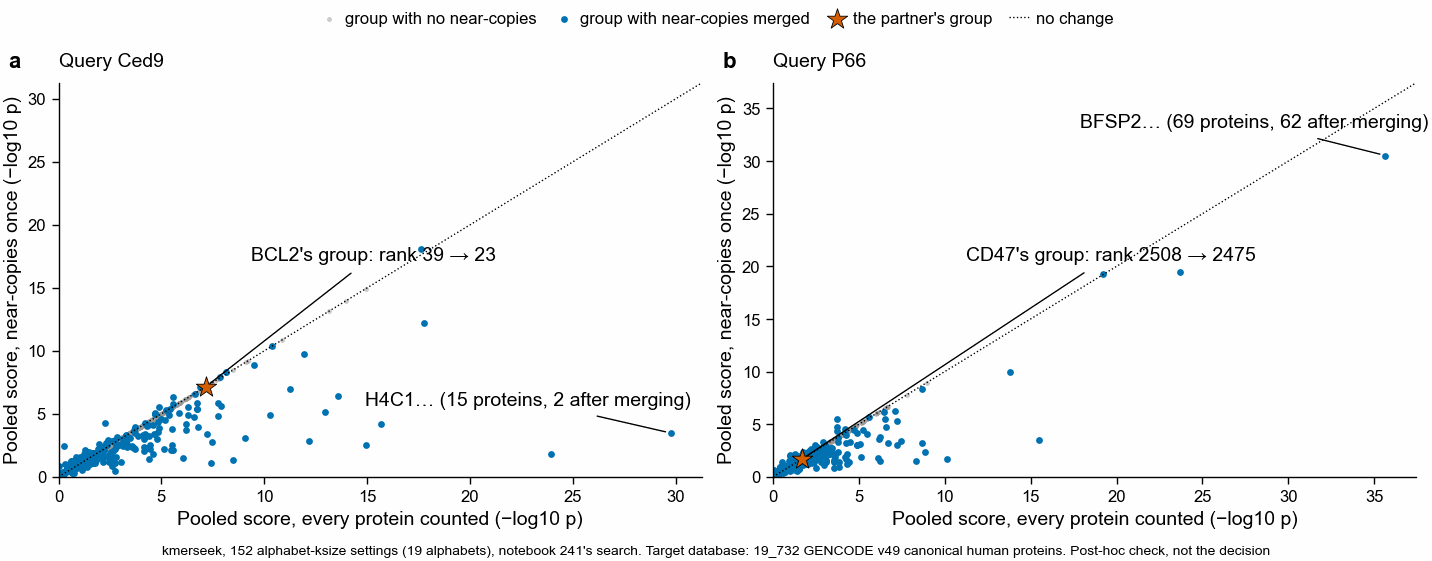

In [7]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 72, ncols=2)
rows = []
for ax, (q, partner, letter) in zip(axs, [("Ced9", "BCL2", "a"), ("P66", "CD47", "b")]):
    d = allg.filter(pl.col("query") == q)
    s = summary.filter(pl.col("query") == q).row(0, named=True)
    merged = d["n_after_merging_copies"] < d["n_proteins"]
    ax.scatter(
        -d.filter(~merged)["log10_p_rule"],
        -d.filter(~merged)["log10_p"],
        s=3,
        lw=0,
        color=pf.GREY,
        alpha=0.6,
        label="group with no near-copies" if letter == "a" else None,
    )
    ax.scatter(
        -d.filter(merged)["log10_p_rule"],
        -d.filter(merged)["log10_p"],
        s=6,
        lw=0,
        color=C["blue"],
        label="group with near-copies merged" if letter == "a" else None,
    )
    ax.scatter(
        [-s["case_group_log10_p"]],
        [-s["posthoc_copies_once_log10_p"]],
        marker="*",
        s=60,
        color=C["vermillion"],
        edgecolor="black",
        lw=0.3,
        zorder=3,
        label="the partner's group" if letter == "a" else None,
    )
    lim = max(-d["log10_p_rule"].min(), -d["log10_p"].min()) * 1.05
    ax.plot(
        [0, lim],
        [0, lim],
        color="black",
        lw=0.5,
        ls=":",
        label="no change" if letter == "a" else None,
    )
    top = d.sort("log10_p_rule").head(1).row(0, named=True)
    ax.annotate(
        f"{top['genes'].split()[0]}… ({top['n_proteins']} proteins, "
        f"{top['n_after_merging_copies']} after merging)",
        (-top["log10_p_rule"], -top["log10_p"]),
        xytext=(-110, 10),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="-", lw=0.5),
    )
    ax.annotate(
        f"{partner}'s group: rank {s['case_group_rank']} → {s['posthoc_copies_once_rank']}",
        (-s["case_group_log10_p"], -s["posthoc_copies_once_log10_p"]),
        xytext=(0.3, 0.55),
        textcoords="axes fraction",
        arrowprops=dict(arrowstyle="-", lw=0.5),
    )
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("Pooled score, every protein counted (−log10 p)")
    ax.set_ylabel("Pooled score, near-copies once (−log10 p)")
    ax.set_title(f"Query {q}", loc="left")
    pf.panel_label(ax, letter)
    rows.append(
        {
            "query": q,
            "partner": partner,
            "groups_with_merged_copies": int(merged.sum()),
            "partner_rank_rule": s["case_group_rank"],
            "partner_rank_copies_once": s["posthoc_copies_once_rank"],
        }
    )
pf.shared_legend(fig, ncol=4)
fig.supxlabel(TOOL + ". Post-hoc check, not the decision", fontsize=5)
pf.save(fig, FIG / "285_posthoc_near_copies_once_ced9_p66")
print(pl.DataFrame(rows))
print("\nCed9, top 10 groups with near-copies counted once:")
print(
    allg.filter(pl.col("query") == "Ced9")
    .sort("log10_p", "group_id")
    .head(10)
    .select(
        "n_proteins",
        "n_after_merging_copies",
        "log10_p",
        "log10_p_rule",
        pl.col("genes").str.slice(0, 70),
    )
)

## 7. Same position as a Pfam Bcl-2 model column

Section 2 counted calls as "at the same position" when they cover the same Ced9 residue,
even if they land on an unrelated stretch of the member (BCL2L1, BCL2L10 and BCL2L2 in
section 3). Here Ced9 and the nine members are placed on the Pfam Bcl-2 profile model
(PF00452.25, 100 columns; hmmsearch, HMMER 3.4), and a call counts at column $c$ only where
**both** its Ced9 residue and its member residue sit in column $c$. Then the same Fisher score
per column, over all nine members.

**Rule, committed before this part was run**
([86403a6](https://github.com/seanome/2024-kmerseek-analysis/commit/86403a6),
`scripts/285_pfam_column_pooling.py`). Null: the same calls with the member side shifted
by $d$ columns, $3 \le |d| \le 40$ (76 shifts). $|d| \le 2$ is left out because a call one or
two columns off can still be the true alignment across an insert. **Pass** if the unshifted
score beats at least 95% of the shifts, AND the family still ranks in the top 10 when its
score is compared with every other group's section-4 score. The column rule only removes
calls, so the family's score can only get weaker than in section 4. The other groups have no
shared model and keep their section-4 scores.

Using the Pfam model puts in what is already known: Ced9 is a Bcl-2 family member. The model
here only sets which residues are at the same position. It adds no evidence to the score.

In [8]:
hits = pl.read_csv(NB / "285_pfam_columns_hmmsearch_hits.csv")
pcalls = pl.read_csv(NB / "285_pfam_columns_calls.csv")
pev = pl.read_csv(NB / "285_pfam_columns_evidence.csv")
pnull = pl.read_csv(NB / "285_pfam_columns_shift_null.csv")
psum = pl.read_csv(NB / "285_pfam_columns_summary.csv").row(0, named=True)
rmap = pl.read_csv(NB / "285_pfam_columns_residue_map.csv")
print("hmmsearch against Bcl-2 (PF00452.25); E-values are for this 10-sequence search:")
print(
    hits.select(
        "protein",
        "full_evalue",
        "domain_i_evalue",
        "domain_score",
        "hmm_from",
        "hmm_to",
        "ali_from",
        "ali_to",
    )
)
print("MCL1's second, weak hit (score -2.2, residues 169-189) is kept by --domE 10;")
print(
    "no Ced9 call on MCL1 touches those residues:",
    pcalls.filter(
        (pl.col("gene") == "MCL1")
        & (pl.col("target_start0") < 189)
        & (pl.col("target_end0") > 168)
    ).height,
    "calls",
)
for k, v in psum.items():
    print(f"{k}: {v}")

seq = {
    p_: "".join(g.sort("residue1")["residue"]) for (p_,), g in rmap.group_by("protein")
}
best = (
    pcalls.sort("neg_ln_p", "alphabet", "k", descending=[True, False, False])
    .group_by("gene", maintain_order=True)
    .first()
    .sort("gene")
)
print("\nEach member's strongest call that is in the same Pfam column on both sides:")
for r in best.iter_rows(named=True):
    qs, ts, n = (
        r["query_start0"],
        r["target_start0"],
        r["query_end0"] - r["query_start0"],
    )
    a, b = seq["Ced9"][qs : qs + n], seq[r["gene"]][ts : ts + n]
    m = "".join("|" if x == y else " " for x, y in zip(a, b))
    print(
        f"\n{r['gene']}  {r['alphabet']} k={r['k']}  E = {r['evalue_database']:.1f} (database), "
        f"p = {r['p_protein']:.4f}  columns {r['first_column']}-{r['last_column']}  "
        f"{m.count('|')} of {n} identical"
    )
    print(f"  {'Ced9':<8}{qs + 1:>4} {a} {qs + n}")
    print(f"  {'':<12} {m}")
    print(f"  {r['gene']:<8}{ts + 1:>4} {b} {ts + n}")
print(
    "\nNo in-column call:",
    sorted(
        set(
            [
                "BAK1",
                "BAX",
                "BCL2",
                "BCL2A1",
                "BCL2L1",
                "BCL2L10",
                "BCL2L2",
                "BOK",
                "MCL1",
            ]
        )
        - set(best["gene"])
    ),
)

hmmsearch against Bcl-2 (PF00452.25); E-values are for this 10-sequence search:
shape: (11, 8)
┌─────────┬─────────────┬─────────────────┬──────────────┬──────────┬────────┬──────────┬────────┐
│ protein ┆ full_evalue ┆ domain_i_evalue ┆ domain_score ┆ hmm_from ┆ hmm_to ┆ ali_from ┆ ali_to │
│ ---     ┆ ---         ┆ ---             ┆ ---          ┆ ---      ┆ ---    ┆ ---      ┆ ---    │
│ str     ┆ f64         ┆ f64             ┆ f64          ┆ i64      ┆ i64    ┆ i64      ┆ i64    │
╞═════════╪═════════════╪═════════════════╪══════════════╪══════════╪════════╪══════════╪════════╡
│ BCL2L1  ┆ 5.6000e-37  ┆ 8.7000e-37      ┆ 115.2        ┆ 1        ┆ 100    ┆ 90       ┆ 188    │
│ BCL2    ┆ 1.5000e-35  ┆ 2.1000e-35      ┆ 110.8        ┆ 1        ┆ 100    ┆ 97       ┆ 195    │
│ BCL2L2  ┆ 2.3000e-33  ┆ 3.9000e-33      ┆ 103.5        ┆ 1        ┆ 100    ┆ 46       ┆ 144    │
│ BAK1    ┆ 1.7000e-32  ┆ 2.9000e-32      ┆ 100.7        ┆ 1        ┆ 100    ┆ 78       ┆ 177    │
│ BAX     ┆ 1.

shape: (56, 3)
┌────────┬──────────────────────┬───────────────────┐
│ column ┆ family_minus_log10_p ┆ members_with_call │
│ ---    ┆ ---                  ┆ ---               │
│ i64    ┆ f64                  ┆ i64               │
╞════════╪══════════════════════╪═══════════════════╡
│ 1      ┆ 0.13                 ┆ 1                 │
│ 2      ┆ 0.13                 ┆ 1                 │
│ 3      ┆ 0.13                 ┆ 1                 │
│ 4      ┆ 0.13                 ┆ 1                 │
│ 5      ┆ 0.13                 ┆ 1                 │
│ 6      ┆ 0.13                 ┆ 1                 │
│ 7      ┆ 0.13                 ┆ 1                 │
│ 8      ┆ 0.13                 ┆ 1                 │
│ 9      ┆ 0.13                 ┆ 1                 │
│ 10     ┆ 0.13                 ┆ 1                 │
│ 11     ┆ 0.13                 ┆ 1                 │
│ 12     ┆ 0.13                 ┆ 1                 │
│ 13     ┆ 0.13                 ┆ 1                 │
│ 14     ┆ 0.

d = 0: 10^-4.42; 0 of 76 shifts as good or better; rank vs section-4 scores 184 of 7_212


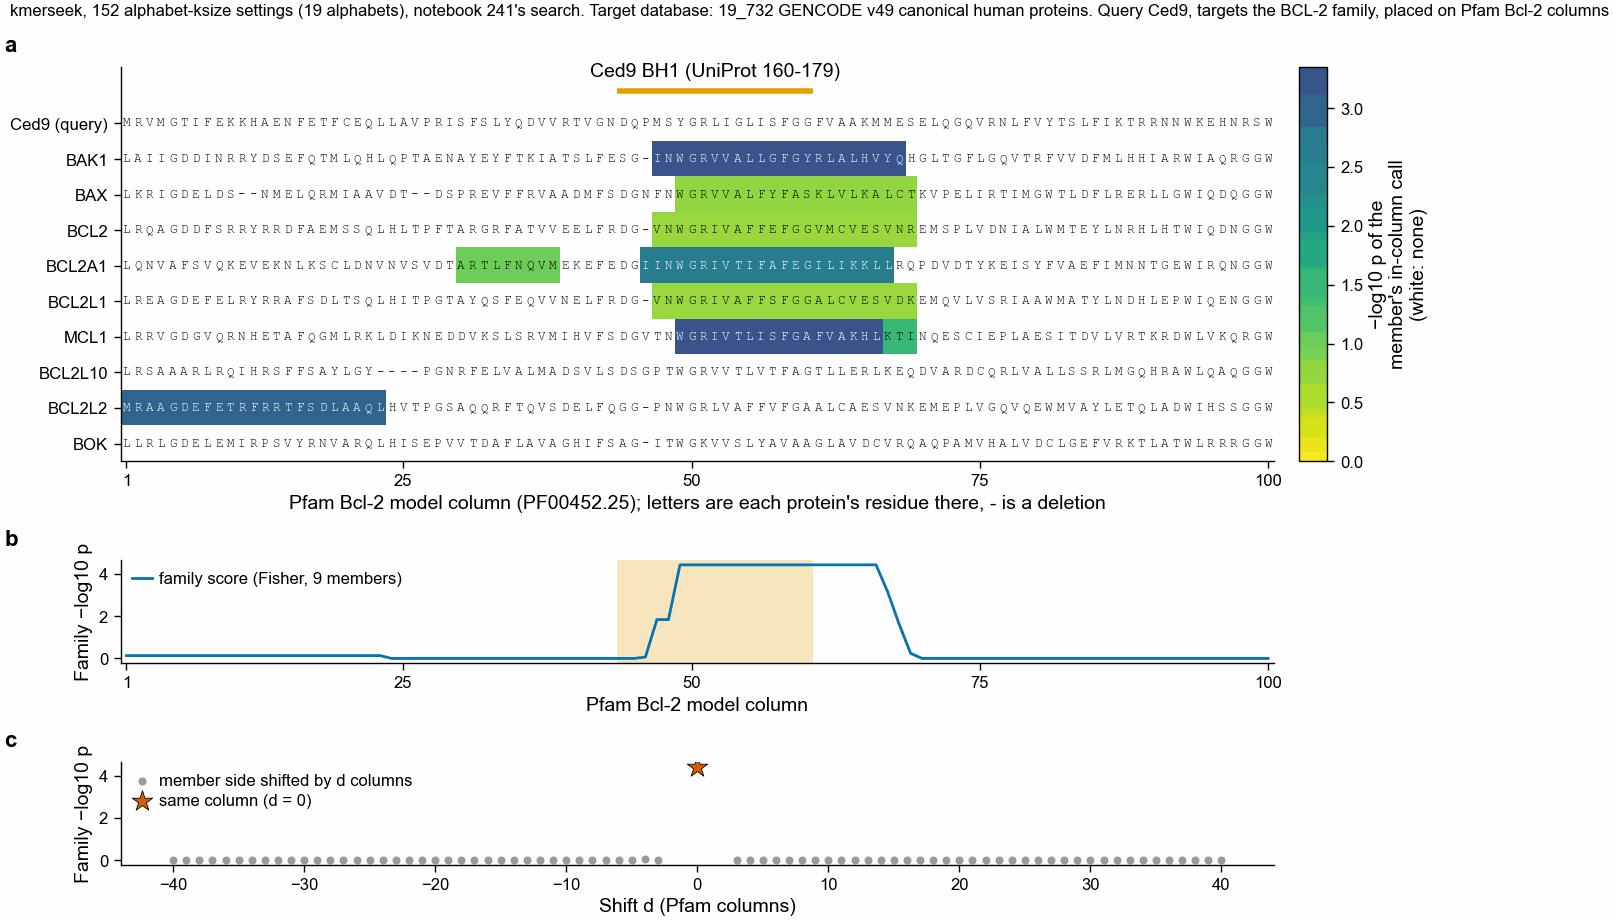

In [9]:
prots = [
    "Ced9",
    "BAK1",
    "BAX",
    "BCL2",
    "BCL2A1",
    "BCL2L1",
    "MCL1",
    "BCL2L10",
    "BCL2L2",
    "BOK",
]
grid = np.full((len(prots), 100), "-", dtype=object)
for i, p_ in enumerate(prots):
    for r in rmap.filter((pl.col("protein") == p_) & (pl.col("column") > 0)).iter_rows(
        named=True
    ):
        grid[i, r["column"] - 1] = r["residue"]
ev = np.zeros((len(prots), 100))
for i, p_ in enumerate(prots[1:], start=1):
    ev[i] = pev[p_].to_numpy()
ced_bh1 = motifs.filter((pl.col("gene") == "Ced9") & (pl.col("motif") == "BH1")).row(
    0, named=True
)
bh1_cols = rmap.filter(
    (pl.col("protein") == "Ced9")
    & pl.col("residue1").is_between(ced_bh1["start1"], ced_bh1["end1"])
    & (pl.col("column") > 0)
)["column"]
fam = -pev["family_log10_p"].to_numpy()
print(
    pl.DataFrame(
        {
            "column": np.arange(1, 101),
            "family_minus_log10_p": fam.round(2),
            "members_with_call": (ev[1:] > 0).sum(axis=0),
        }
    ).filter(pl.col("members_with_call") > 0)
)

fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 118 * pf.MM), layout="constrained")
gs = fig.add_gridspec(
    3, 2, height_ratios=[len(prots) + 1.5, 3, 3], width_ratios=[40, 1]
)
a1, cax = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
a2, a3 = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[2, 0])
cmap = mpl.colors.ListedColormap(
    plt.get_cmap("viridis")(np.linspace(0.25, 1, 256))[::-1]
)
cmap.set_bad("white")
im = a1.imshow(
    np.ma.masked_where(ev <= 0, ev),
    aspect="auto",
    cmap=cmap,
    interpolation="nearest",
    extent=(0.5, 100.5, len(prots) - 0.5, -0.5),
    vmin=0,
    vmax=float(ev.max()),
)
for i in range(len(prots)):
    for c in range(100):
        a1.text(
            c + 1,
            i,
            grid[i, c],
            ha="center",
            va="center",
            family="monospace",
            size=4.5,
            color="white" if ev[i, c] > 0.6 * ev.max() else "black",
        )
a1.plot(
    [bh1_cols.min() - 0.5, bh1_cols.max() + 0.5],
    [-0.9, -0.9],
    color=C["orange"],
    lw=2,
    solid_capstyle="butt",
    clip_on=False,
)
a1.text(
    (bh1_cols.min() + bh1_cols.max()) / 2,
    -1.2,
    "Ced9 BH1 (UniProt 160-179)",
    ha="center",
    va="bottom",
)
a1.set_yticks(range(len(prots)), ["Ced9 (query)"] + prots[1:])
a1.set_xlim(0.5, 100.5)
a1.set_ylim(len(prots) - 0.5, -1.6)
a1.set_xticks([1, 25, 50, 75, 100])
a1.set_xlabel(
    "Pfam Bcl-2 model column (PF00452.25); letters are each protein's residue there, - is a deletion"
)
fig.colorbar(
    im, cax=cax, label="−log10 p of the\nmember's in-column call\n(white: none)"
)
a2.plot(
    np.arange(1, 101),
    fam,
    color=C["blue"],
    lw=1,
    label="family score (Fisher, 9 members)",
)
a2.axvspan(
    bh1_cols.min() - 0.5, bh1_cols.max() + 0.5, color=C["orange"], alpha=0.25, lw=0
)
a2.set_xlim(0.5, 100.5)
a2.set_xticks([1, 25, 50, 75, 100])
a2.set_xlabel("Pfam Bcl-2 model column")
a2.set_ylabel("Family −log10 p")
a2.legend(loc="upper left", frameon=False)
sh = pnull.filter(pl.col("shift") != 0)
a3.scatter(
    sh["shift"],
    -sh["log10_p"],
    s=6,
    color=pf.GREY,
    label="member side shifted by d columns",
)
a3.scatter(
    [0],
    [-psum["column_rule_log10_p"]],
    marker="*",
    s=60,
    color=C["vermillion"],
    edgecolor="black",
    lw=0.3,
    label="same column (d = 0)",
)
a3.set_xlabel("Shift d (Pfam columns)")
a3.set_ylabel("Family −log10 p")
a3.legend(loc="upper left", frameon=False)
for ax, letter in zip([a1, a2, a3], "abc"):
    pf.panel_label(ax, letter, dx_pt=-42)
fig.suptitle(
    TOOL + ". Query Ced9, targets the BCL-2 family, placed on Pfam Bcl-2 columns",
    fontsize=6,
    x=0.01,
    ha="left",
)
pf.save(fig, FIG / "285_ced9_bcl2_family_pfam_columns")
print(
    f"d = 0: 10^{psum['column_rule_log10_p']:.2f}; {psum['shifts_as_good_or_better']} of "
    f"{psum['n_shifts']} shifts as good or better; rank vs section-4 scores "
    f"{psum['rank_vs_part1_groups']} of {psum['n_groups']:_}"
)

## 8. Verdict

shape: (2, 8)
┌───────┬─────────┬─────────────────┬──────────┬────────────┬──────────────────────────────────┬──────────────────┬──────────────┐
│ query ┆ partner ┆ case_group_rank ┆ n_groups ┆ pass_top10 ┆ random_sets_frac_better_or_equal ┆ pass_random_sets ┆ shuffle_null │
│ ---   ┆ ---     ┆ ---             ┆ ---      ┆ ---        ┆ ---                              ┆ ---              ┆ ---          │
│ str   ┆ str     ┆ i64             ┆ i64      ┆ bool       ┆ f64                              ┆ bool             ┆ str          │
╞═══════╪═════════╪═════════════════╪══════════╪════════════╪══════════════════════════════════╪══════════════════╪══════════════╡
│ Ced9  ┆ BCL2    ┆ 39              ┆ 7212     ┆ false      ┆ 0.0                              ┆ true             ┆ pending      │
│ P66   ┆ CD47    ┆ 2508            ┆ 7212     ┆ false      ┆ 0.339                            ┆ false            ┆ pending      │
└───────┴─────────┴─────────────────┴──────────┴────────────┴────────

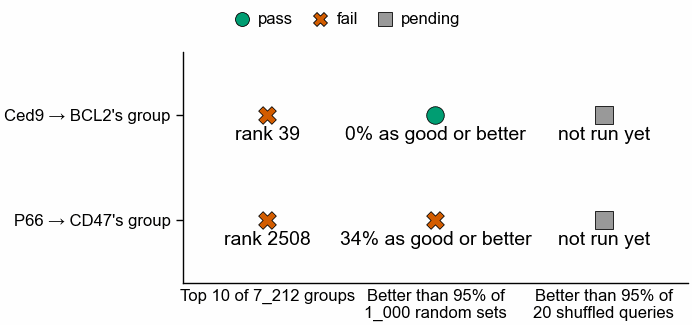

In [10]:
v = summary.select(
    "query",
    "partner",
    "case_group_rank",
    "n_groups",
    "pass_top10",
    "random_sets_frac_better_or_equal",
    "pass_random_sets",
    "shuffle_null",
)
print(v)
for r in summary.iter_rows(named=True):
    ok = r["pass_top10"] and r["pass_random_sets"]
    print(
        f"{r['query']} -> {r['partner']}: top 10 {'pass' if r['pass_top10'] else 'FAIL'} "
        f"(rank {r['case_group_rank']}); random sets {'pass' if r['pass_random_sets'] else 'FAIL'} "
        f"({r['random_sets_frac_better_or_equal']:.3f} as good or better); shuffles pending. "
        f"Overall: {'cannot pass yet' if ok else 'FAIL'}"
    )
ps = pl.read_csv(NB / "285_pfam_columns_summary.csv").row(0, named=True)
print(
    f"Ced9 -> BCL-2 family on Pfam columns: shifts {'pass' if ps['pass_shift_null'] else 'FAIL'} "
    f"({ps['shifts_as_good_or_better']} of {ps['n_shifts']} as good or better); top 10 "
    f"{'pass' if ps['pass_top10'] else 'FAIL'} (rank {ps['rank_vs_part1_groups']})"
)

checks = [
    "Top 10 of 7_212 groups",
    "Better than 95% of\n1_000 random sets",
    "Better than 95% of\n20 shuffled queries",
]
style = {
    "pass": ("o", C["bluish_green"]),
    "fail": ("X", C["vermillion"]),
    "pending": ("s", pf.GREY),
}
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 42)
for yi, r in enumerate(summary.iter_rows(named=True)):
    states = [
        "pass" if r["pass_top10"] else "fail",
        "pass" if r["pass_random_sets"] else "fail",
        "pending",
    ]
    notes = [
        f"rank {r['case_group_rank']}",
        f"{r['random_sets_frac_better_or_equal']:.0%} as good or better",
        "not run yet",
    ]
    for xi, (st, note) in enumerate(zip(states, notes)):
        m, col = style[st]
        ax.scatter(xi, yi, marker=m, s=40, color=col, edgecolor="black", lw=0.3)
        ax.annotate(
            note, (xi, yi), xytext=(0, -9), textcoords="offset points", ha="center"
        )
for st, (m, col) in style.items():
    ax.scatter([], [], marker=m, s=25, color=col, edgecolor="black", lw=0.3, label=st)
ax.set_xticks(range(3), checks)
ax.set_yticks(
    range(summary.height),
    [f"{q} → {p}'s group" for q, p in zip(summary["query"], summary["partner"])],
)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(summary.height - 0.4, -0.6)
ax.tick_params(axis="x", length=0)
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / "285_decision_ced9_p66")

# Summary and Conclusions

## Background

Ced9 → BCL2 and P66 → CD47 are the two remote pairs kmerseek misses as single proteins in
notebook 241's human search. PR 125 showed that counting agreement across alphabets does not
rescue them. This notebook pools the calls of every member of the partner's Ensembl paralog
group at the same query residue, with the score and pass rule committed before the run.

## Summary and Conclusions

* Pooling across the BCL-2 family lifts BCL2 from rank 10_025 of 19_732 proteins to rank 39
  of 7_212 paralog groups for Ced9, short of the top-10 rule, so the test fails.
* The nine-member BCL-2 family scores $p = 10^{-7.2}$ for Ced9, better than all 1_000
  random nine-protein sets (median $10^{-1.9}$) and all 41 other nine-member paralog groups.
* Ced9 residue 168 (BH1) carries the pooled peak: 8 of 9 BCL-2 family members have a call
  there, and 5 of the 8 sit in register on the member's own BH1.
* 35 of the 38 groups above BCL2's have more than 9 members (median 21.5) and 24 hold
  ≥90%-identical copies; counting those copies once moves BCL2's group only to rank 23.
* Counting only calls in the same Pfam Bcl-2 column on both sides, 6 of 9 members back
  Ced9's BH1 (column 49): p = 10^-4.4, better than all 76 shifted alignments, but rank 184.
* CD47 has no Ensembl paralog, so pooling cannot help P66 → CD47: its group of one ranks
  2_508 of 7_212, and 34% of random single proteins score as well or better.
* The dipeptide-shuffled-query null is pending: notebook 283's human indexes, which the
  notebook 284 shuffle job needs, failed to build on 2026-10-13.

## Analysis Details

Groups come from Ensembl 115 paralog pairs (257_744 pairs inside the 19_732 canonical
proteins), joined into connected sets; 4_371 genes have no paralog and the largest group has
177 genes (a KRAB zinc-finger family). Each region's whole-database E-value becomes a
per-protein $p$ by the protein's share of database residues. Evidence is taken per Ced9
residue, so members count as "in the same position" when their calls cover the same query
residue; this does not check that the member's stretches are at the same place in the
family's alignment, and 3 of BCL2's 8 calls (BCL2L1, BCL2L10, BCL2L2) are not on BH1.
Fisher's method treats members as independent. They are not: paralogs share sequence, so a
chance call on one tends to repeat on its relatives, and the random-set null (unrelated
proteins) is too easy. The same-size comparison with real paralog groups is the fairer
one, and BCL2's family is first of the 42 nine-member groups there; this comparison was
added after the run. Bigger groups have more members for chance calls to repeat on, which is
why the groups above BCL2's are mostly large: 35 of the 38 have more than 9 members.

## Supplementary Information

- Scripts: `scripts/285_paralog_groups.py`, `scripts/285_family_pooled_evidence.py`
  (rule committed in d184330 before the first run), `scripts/make_nb285.py`.
- Tables: `notebooks/285_*.csv`. Figures: `figures/285/*.{pdf,svg,png}`.
- Random-set draws: numpy `default_rng(285)`, 1_000 draws per case.
- Pfam columns (section 7): hmmsearch with `--domE 10 --incdomE 10`, which also kept a
  weak second MCL1 hit (score -2.2, residues 169-189); no call touches it. The Bcl-2 model's
  Pfam seed and Ced9's known family membership decide the columns, not kmerseek.

## References

- Ensembl 115 (September 2025), BioMart `hsapiens_gene_ensembl`, paralog attributes.
- GENCODE v49 canonical protein translations.
- UniProt entries P41958, P10415, Q07817, Q07820, Q16611, Q07812, Q16548, Q9HD36, Q92843,
  Q9UMX3 (motif features), accessed 2026-10-13.
- Fisher, R. A. *Statistical Methods for Research Workers*. Edinburgh: Oliver and Boyd, 1925.
- Altschul, S. F., and B. W. Erickson. "Significance of Nucleotide Sequence Alignments: A
  Method for Random Sequence Permutation That Preserves Dinucleotide and Codon Usage."
  *Molecular Biology and Evolution* 2, no. 6 (1985): 526–38.